In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys

import xtrack as xt
import xpart as xp
import xobjects as xo
import xcoll as xc
from pathlib import Path
import json
import time

In [2]:
def remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2):
    "Remove apertures of off-momentum BPMs which give flanges as bottlenecks"
    tt = line.get_table()
    tw = line.twiss()
    mask_disp = 5*np.sqrt(tw.betx*exn*pmass/nrj)+n_buckets*bucket_height*tw.dx > 0.025
    mask_bpm = ['bp' in name for name in tt.name]
    mask_aper = np.array(['aper' in name for name in tt.name])
    offmom_bpms = tt.name[mask_disp & mask_bpm & ~mask_aper]
    aper_to_remove = [f'{name}{suffix}' for name in offmom_bpms for suffix in ('.a_aper', '.b_aper')]
    line.remove(aper_to_remove)
    
def install_tidp(line, block_mvt=29e-3):
    tidp_ap_tot = 147e-3
    line.discard_tracker()
    tidp = xc.EverestCollimator(length=4.3, material=xc.materials.Carbon, jaw_L= tidp_ap_tot/2 + block_mvt, jaw_R = -tidp_ap_tot/2 + block_mvt)
    line.collimators.install(names=['tidp.11434'], elements=[tidp])
    return tidp

def install_tcsm(line, gap=5):
    tcsm = xc.EverestCollimator(length=1.83, gap=gap, material=xc.materials.Carbon) # length is 1.83
    line.collimators.install(names=['tcsm.51932'], elements=[tcsm])
    return tcsm

In [3]:
#Crab settings, only one was on during MD, real phase is unknown
crab_voltage = 1e6
crab_frequency = 400.787294e6
phase = -np.pi/2

In [4]:
# Parameters
qx = 20.13
qy = 20.18
xi_x = 0.5
xi_y = 0.5

num_particles = 1000
num_turns = 3000
plane = 'H'
start_at_turn= 500
nemitt_x = 2e-6
nemitt_y = 2e-6
ramping_turns = 100
use_individual_kicks = True
coll_gap = 5

In [5]:
line = xt.load('../sps_with_aperture_inj_q20_beam_sagitta4.json')
env = line.env
cavity_elements, cavity_names = line.get_elements_of_type(xt.Cavity)
for name in cavity_names:
    line[name].frequency = 200e6
    line[name].lag = 180
    line[name].voltage = 0
# line['acl.31735'].voltage = 0 #setting 800 cav to 0V
line['actcse.31632'].voltage = 3.0e6

tw = line.twiss()
remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2)

# Installing errors
# b1, b2, b3, b4, b5, b6 = error_variants[error_variant_name]
# tte = env.elements.get_table()
# mask_rbends = tte.element_type == 'RBend'
# mask_quads = tte.element_type == 'Quadrupole'
# mask_sextupoles = tte.element_type == 'Sextupole'

# mba = tte.rows[mask_rbends].rows['mba.*'].name
# mbb = tte.rows[mask_rbends].rows['mbb.*'].name
# qf = tte.rows[mask_quads].rows['qf.*'].name
# qd = tte.rows[mask_quads].rows['qd.*'].name
# lsf = tte.rows[mask_sextupoles].rows['lsf.*'].name
# lsd = tte.rows[mask_sextupoles].rows['lsd.*'].name

# env.vars['qph_setvalue'] = 0.0
# env.vars['qpv_setvalue'] = 0.0

# Set the strengths according to Hannes' measurements
# for nn in mba:
#     env[nn].knl = np.array([b1*0., b2*0., b3*2.12e-3, b4*0., b5*-5.74, b6*0.])

# for nn in mbb:
#     env[nn].knl = np.array([b1*0., b2*0., b3*-3.19e-3, b4*0., b5*-5.10, b6*0.])

# for nn in qf:
#     env[nn].knl = np.array([b1*0., b2*0., b3*0., b4*0.75e-1, b5*0., b6*-0.87e3])

# for nn in qd:
#     env[nn].knl = np.array([b1*0., b2*0., b3*0., b4*-2.03e-1, b5*0., b6*2.04e3])

# New model 
# for nn in mba:
#     env[nn].knl = np.array([b1*0., b2*0., b3*8.92863062376558e-06,   b4*0.,       b5*-1.6271899631371554,  b6*0.])
# for nn in mbb:
#     env[nn].knl = np.array([b1*0., b2*0., b3*-2.606543641240525e-05,  b4*0.,       b5*-1.1800693058580867,  b6*0.])
# for nn in qf:
#     env[nn].knl = np.array([b1*0., b2*0., b3*0.,        b4*0.025520870077609926,  b5*0.,     b6*-114.8869977018476])
# for nn in qd:
#     env[nn].knl = np.array([b1*0., b2*0., b3*0.,        b4*-0.029783873625363777, b5*0.,     b6*-749.9978975055122])

# Installing crabs
crab1 = xt.CrabCavity(crab_voltage=crab_voltage, frequency = crab_frequency, phase = phase)
crab2 = xt.CrabCavity(crab_voltage=0, frequency = crab_frequency, phase=phase)
env.element_dict['acfcah.61738'] = crab1
env.element_dict['acfcah.61739'] = crab2
tt = line.get_table()


#Matching tune and chromaticity
env.vars['qph_setvalue'] = xi_x
env.vars['qpv_setvalue'] = xi_y
opt = line.match(
    method='6d', # <- passed to twiss
    vary=[
        xt.VaryList(['kqf0', 'kqd0'], step=1e-8, tag='quad'),
        xt.VaryList(['qph_setvalue', 'qpv_setvalue'], step=1e-4, tag='sext'),
    ],
    targets = [
        xt.TargetSet(qx=qx, qy=qy, tol=1e-6, tag='tune'),
        xt.TargetSet(dqx=xi_x*qx, dqy=xi_y*qy, tol=1e-2, tag='chrom'),
    ])

tw = line.twiss()
tt = line.get_table()

Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]

/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:793: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:3783: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians) instead. Note that if both `pn` and `phase_n` are set, the effect is the sum of the two with `pn` converted to radians.
  self._warn_if_deprecated_phase_is_nonzero(pn, 'pn', 'phase_n')
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam

Done loading line from dict.           


/Users/lisepauwels/miniforge3/envs/xcoll/lib/python3.13/site-packages/xdeps/tasks.py:252: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  ref._set_value(value)


                                             
Optimize - start penalty: 0.1733                            
Matching: model call n. 8 penalty = 9.2077e-04              
Optimize - end penalty:  0.000920772                            


In [6]:
adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
                        amplitude=0.0005, use_individual_kicks=use_individual_kicks, start_at_turn=start_at_turn)

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/2273783697.py:1: FutureWarning: `Line.get_s_position` is deprecated and will be removed in a future version. Use `tt = line.get_table()` and then `tt.s` to get all s positions or `tt['s', 'myelem']` for one specific s position. This deprecation is part of the interface cleanup in view of the 1.0 release.
  adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
/Users/lisepauwels/Xsuite/xcoll/xcoll/beam_elements/blowup.py:69: FutureWarning: Warning: `at_s` is deprecated and will be removed in the future. Please use `at` instead.
  warn("Warning: `at_s` is deprecated and will be removed in "


Slicing line:   0%|          | 0/32246 [00:00<?, ?it/s]

In [7]:
tidp = install_tidp(line, block_mvt=29e-3)
tcsm = install_tcsm(line, gap=coll_gap)
line.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)
tw = line.twiss()

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/3762357103.py:16: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.install(names=['tidp.11434'], elements=[tidp])


Slicing line:   0%|          | 0/32247 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/3762357103.py:21: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.install(names=['tcsm.51932'], elements=[tcsm])


Slicing line:   0%|          | 0/32245 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/1029094370.py:3: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)


In [8]:
part = xp.generate_matched_gaussian_bunch(nemitt_x=nemitt_x,
                                          nemitt_y=nemitt_y,
                                          sigma_z=0.224, num_particles=num_particles, line=line)

*** Maximum RMS bunch length 0.23610110400434295m.
... distance to target bunch length: -2.2226e-01
... distance to target bunch length: 5.5784e-03
... distance to target bunch length: 5.2361e-03
... distance to target bunch length: -6.3267e-03
... distance to target bunch length: 1.9948e-03
... distance to target bunch length: -3.8258e-04
... distance to target bunch length: 5.3833e-05
... distance to target bunch length: 1.2594e-06
... distance to target bunch length: -1.0995e-10
... distance to target bunch length: 1.2805e-07
--> Bunch length: 0.22399999989004865
--> Emittance: 0.27972269028710633


In [9]:
adt.calibrate_by_emittance(nemitt=nemitt_x, twiss=tw)

In [ ]:
#Tracking
line.discard_tracker()
line.build_tracker(_context=xo.ContextCpu(omp_num_threads='auto'))
line.scattering.enable()
print('Ramping crab cavities')
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    line['acfcah.61738'].crab_voltage = crab_voltage * turn / 100
    line['acfcah.61739'].crab_voltage = 0 * turn / 100
    line.track(part, num_turns=1, with_progress=False)

print(line['acfcah.61738'].crab_voltage)
print(line['acfcah.61739'].crab_voltage)
print('Crab cavities ramped up. Letting settle for 400 turns...')
line.track(part, num_turns=400, with_progress=True)

print('Ramping up ADT up to 0.05 in 100 turns')
adt.activate()
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.0005 * turn
    line.track(part, num_turns=1, with_progress=False)

print('First ADT ramp up done! Tracking 400 turns...')
line.track(part, num_turns=400, with_progress=True)

for turn in range(1,500):
    if turn % 50 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.05 + 0.0001 * turn
    line.track(part, num_turns=1, with_progress=False)

print('Second ADT ramp up done! Tracking remaining 2500 turns...')
line.track(part, num_turns=2500, with_progress=True)
adt.deactivate()
line.scattering.disable()

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/3281825522.py:2: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.enable()


Ramping crab cavities
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
1000000.0
0.0
Crab cavities ramped up. Letting settle for 400 turns...


Tracking:   0%|          | 0/400 [00:00<?, ?it/s]

Ramping up ADT up to 0.05 in 100 turns
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
First ADT ramp up done! Tracking 400 turns...


Tracking:   0%|          | 0/400 [00:00<?, ?it/s]

  Turn 50
  Turn 100
  Turn 150
  Turn 200
  Turn 250
  Turn 300
  Turn 350
  Turn 400
  Turn 450
Second ADT ramp up done! Tracking remaining 2500 turns...


Tracking:   0%|          | 0/2500 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_10133/3281825522.py:36: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.disable()


In [11]:
xc.__version__

'0.10.1'

In [12]:
ThisLM = xc.LossMap(line = line, line_is_reversed=False, part=part, interpolation=False)

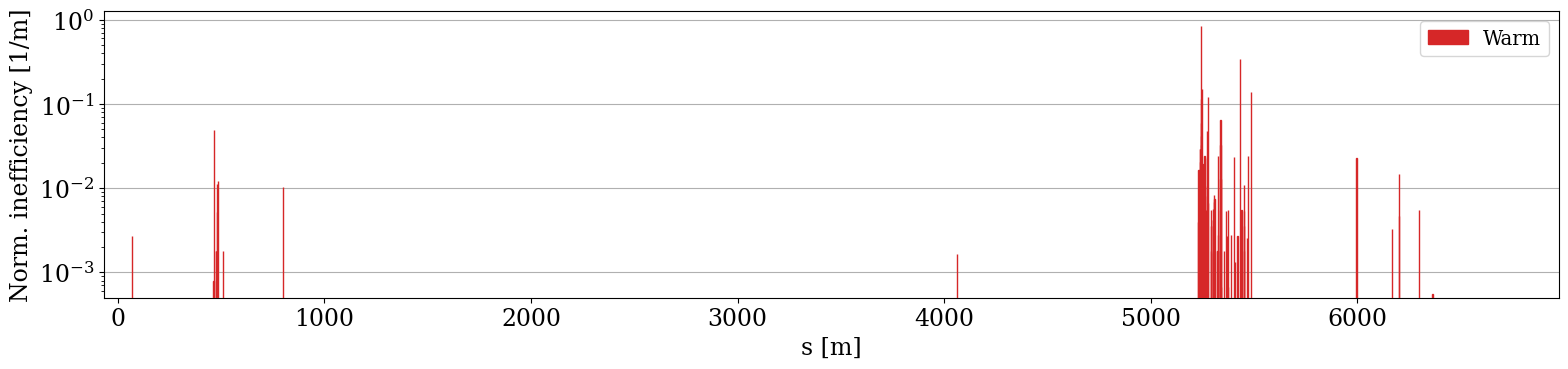

(<Figure size 1600x400 with 1 Axes>,
 <Axes: xlabel='s [m]', ylabel='Norm. inefficiency [1/m]'>)

In [19]:
ThisLM.plot()

In [39]:
line['tcsm.51932'].to_dict()

RecursionError: maximum recursion depth exceeded

In [14]:
part2 = part.copy()

In [17]:
ThisLM3 = xc.LossMap(line = line, line_is_reversed=False, part=part2, interpolation=True)

Performing the aperture losses refinement.


ValueError: There is already an element with name _interp_aper_0

In [18]:
ThisLM.update_metadata({"warm_regions" : [[0.0, tt.s[-1]]]})

In [24]:
idxs, counts = np.unique(part.at_element, return_counts=True)

In [26]:
np.argmax(counts), np.max(counts)

(np.int64(26), np.int64(324))

In [27]:
line.element_names[np.argmax(counts)]

'mba.10030..8_aper2'

In [28]:
np.where(line.element_names == 'tcsm.51932')

ValueError: Calling nonzero on 0d arrays is not allowed. Use np.atleast_1d(scalar).nonzero() instead. If the context of this error is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.

In [32]:
np.where(np.array(line.element_names)== 'tcsm.51932')

(array([24300]),)

In [35]:
line.element_names[idxs[np.argmax(counts)]]

'vttm.52002.b_aper'

In [38]:
line.element_dict['tcsm.51932'].jaw_L

np.float64(0.0066479799883847335)